# Figuras auxiliares

## Qué significa una componente tratada

Se usan las mismas cinco unidades de la muestra común de 93 tratadas en los tres paneles. Cada círculo es una **unidad tratada**, no una cámara: T88 agrupa dos cámaras. Una componente reúne unidades cuyos círculos se traslapan directamente o están conectados por otras unidades. La escala y el encuadre se mantienen fijos para comparar radios.

In [1]:
from nbsetup import *
from matplotlib.patches import Circle
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components
from pipeline import Datos, Panel, muestra_comun

RADIOS = (100, 200, 300)
datos = Datos()
emparejamientos, comunes = muestra_comun(datos)
assert len(comunes) == 93

In [2]:
# Elegir el componente de cinco dentro de las tratadas efectivamente emparejadas.
panel_300 = Panel(emparejamientos[300])
membresia_300 = pd.DataFrame({
    'uid': panel_300.unidades.uid, 'cluster': panel_300.clusters,
})
membresia_300 = membresia_300[membresia_300.uid.str.startswith('T')]
tamanos = membresia_300.groupby('cluster').size()
clusters_de_cinco = tamanos[tamanos == 5].index
assert len(clusters_de_cinco) == 1
uid_cinco = sorted(membresia_300.loc[
    membresia_300.cluster == clusters_de_cinco[0], 'uid'
])
ids = [int(uid[1:]) for uid in uid_cinco]
assert all(set(uid_cinco) <= set(e.pares.tratada) for e in emparejamientos.values())

# Un enlace existe cuando dos de los cinco círculos comparten área.
enlaces = {}
componentes_cinco = {}
componentes_muestra = {}
for radio in RADIOS:
    panel = Panel(emparejamientos[radio])
    grupos = pd.DataFrame({'uid': panel.unidades.uid, 'cluster': panel.clusters})
    componentes_muestra[radio] = grupos.loc[
        grupos.uid.str.startswith('T'), 'cluster'
    ].nunique()
    geometria = (emparejamientos[radio].features.tratadas.unidades
                 .set_index('unidad_id').loc[ids].geometry)
    enlaces[radio] = [(a, b) for i, a in enumerate(ids) for b in ids[i + 1:]
                      if geometria.loc[a].intersects(geometria.loc[b])]
    posicion = {unidad: i for i, unidad in enumerate(ids)}
    vecinos = enlaces[radio]
    ady = coo_matrix((np.ones(2 * len(vecinos)),
                      ([posicion[a] for a, b in vecinos]
                        + [posicion[b] for a, b in vecinos],
                       [posicion[b] for a, b in vecinos]
                        + [posicion[a] for a, b in vecinos])),
                     shape=(len(ids), len(ids)))
    componentes_cinco[radio] = connected_components(ady, directed=False)[0]
assert [componentes_cinco[r] for r in RADIOS] == [5, 4, 1]
assert [componentes_muestra[r] for r in RADIOS] == [93, 86, 72]
print('Cinco unidades:', ', '.join(uid_cinco))
print('Componentes entre estas cinco:', componentes_cinco)
print('Componentes entre las 93 tratadas:', componentes_muestra)
print('Pares que se traslapan:', enlaces)

Cinco unidades: T3, T45, T55, T88, T95
Componentes entre estas cinco: {100: 5, 200: 4, 300: 1}
Componentes entre las 93 tratadas: {100: 93, 200: 86, 300: 72}
Pares que se traslapan: {100: [], 200: [(88, 95)], 300: [(3, 55), (3, 95), (45, 88), (88, 95)]}


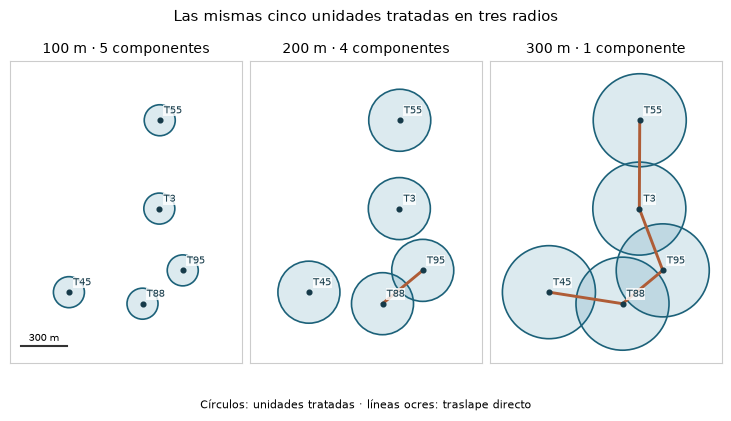

In [6]:
centros = (emparejamientos[300].features.tratadas.centros
           .set_index('unidad_id').loc[ids].geometry)
xy = {unidad: (p.x, p.y) for unidad, p in centros.items()}
xs, ys = np.array(list(xy.values())).T
margen = max(RADIOS) + 80
lim_x = (xs.min() - margen, xs.max() + margen)
lim_y = (ys.min() - margen, ys.max() + margen)

with plt.rc_context({'font.family': 'DejaVu Sans', 'font.size': 9,
                     'axes.titlesize': 10, 'svg.fonttype': 'none'}):
    fig, axes = plt.subplots(1, 3, figsize=(7.2, 4.1),
                             layout='constrained')
    for ax, radio in zip(axes, RADIOS):
        for unidad in ids:
            x, y = xy[unidad]
            ax.add_patch(Circle((x, y), radio,
                                facecolor=(0.10, 0.45, 0.60, 0.15),
                                edgecolor='#1C6179', lw=1.2, zorder=1))
        for a, b in enlaces[radio]:
            ax.plot([xy[a][0], xy[b][0]], [xy[a][1], xy[b][1]],
                    color='#AF5C36', lw=2.1, zorder=2)
        for unidad in ids:
            x, y = xy[unidad]
            ax.plot(x, y, 'o', ms=3.4, color='#153A49', zorder=3)
            ax.annotate(f'T{unidad}', (x, y), xytext=(3, 5),
                        textcoords='offset points', fontsize=7.5,
                        color='#153A49', zorder=4,
                        bbox={'facecolor': 'white', 'edgecolor': 'none',
                              'alpha': 0.82, 'pad': 0.3})
        ax.set_xlim(*lim_x)
        ax.set_ylim(*lim_y)
        ax.set_aspect('equal', adjustable='box')
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f'{radio} m · {componentes_cinco[radio]} '
                     f'{"componente" if componentes_cinco[radio] == 1 else "componentes"}')
        for spine in ax.spines.values():
            spine.set_color('#CCCCCC')
    # Una escala única basta: el encuadre es el mismo en los tres paneles.
    x0, y0 = lim_x[0] + 70, lim_y[0] + 105
    axes[0].plot([x0, x0 + 300], [y0, y0], color='#333333', lw=1.5)
    axes[0].text(x0 + 150, y0 + 35, '300 m', ha='center', fontsize=7)
    fig.suptitle('Las mismas cinco unidades tratadas en tres radios', fontsize=11)
    fig.supxlabel('Círculos: unidades tratadas · líneas ocres: traslape directo',
                  fontsize=8)
    destino = ROOT / 'figures' / 'componente-tratado-100-200-300.svg'
    fig.savefig(destino, format='svg')
    plt.show()

En estas cinco unidades, los componentes pasan de **5 → 4 → 1** al crecer el radio. En la muestra completa de 93 tratadas pasan de **93 → 86 → 72**. La unión es por conectividad: una unidad no necesita traslaparse con las otras cuatro para formar parte de la misma componente. Los 93 controles emparejados no se traslapan y conservan un cluster propio cada uno; por eso la tabla de estimación reporta **186, 179 y 165 clusters** a 100, 200 y 300 m, respectivamente.